# Sifre og «ikke tall» med CNN (PyTorch)

Modellen fra `01_mnist_cnn.ipynb` kan bare svare med et siffer. Softmax fordeler alltid 100 % på de ti sifrene, så når du skribler på nettsiden, velger modellen bare det sifferet skriblingen ligner mest på, ofte med nesten 100 % sikkerhet.

Her legger vi til en **11. kategori, «ikke tall»**, og trener modellen på eksempler på ting som ikke er sifre.

Plan:
1. Oppsett
2. Forbehandling som på nettsiden
3. Sifre: MNIST
4. «Ikke tall»: bokstaver, tegninger, skribling og to sifre ved siden av hverandre
5. Definere CNN-et (som i notatbok 01, men med 11 utganger)
6. Trening
7. Evaluering: hvor mange tall blir godtatt, og hvor mange ikke-tall blir avvist?
8. Eksport til ONNX

## 1. Oppsett

In [1]:
import io
import json
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

# Bruk Apple-GPU (MPS) hvis tilgjengelig, ellers CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "- enhet:", device)

# Faste startverdier, så datasettet blir likt hver gang notatboken kjøres
rng = np.random.default_rng(0)
torch.manual_seed(0)

IKKE_TALL = 10
KLASSENAVN = [str(i) for i in range(10)] + ["ikke tall"]

PyTorch 2.15.0 - enhet: mps


## 2. Forbehandling som på nettsiden

Nettsiden klipper ut tegningen, skalerer den så den lengste siden blir 20 piksler, og sentrerer den i en 28×28-ramme. Vi gjør nøyaktig det samme med **alle** bildene her, også MNIST-sifrene.

Hvorfor det er viktig: Hvis sifrene og «ikke tall»-bildene var forbehandlet på hver sin måte, kunne modellen lært å skille dem på forbehandlingen (plassering, størrelse, strektykkelse) i stedet for på formen. Da ville den bommet på nettsiden, der alt forbehandles likt.

- `sentrer()` gjør det samme som `toTensor()` i `docs/index.html`.
- `tegn_strøk()` tegner streker på et 280×280-lerret med samme pensel som nettsiden: 18 piksler bred, med runde ender.

In [2]:
def sentrer(bilde):
    """Klipp ut det som er tegnet, skaler lengste side til 20 px og sentrer i 28×28."""
    ys, xs = np.nonzero(bilde)
    ut = np.zeros((28, 28), np.uint8)
    if len(xs) == 0:
        return ut
    utsnitt = bilde[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, b = utsnitt.shape
    skala = 20 / max(b, h)
    nb, nh = max(1, round(b * skala)), max(1, round(h * skala))
    liten = Image.fromarray(utsnitt).resize((nb, nh), Image.BILINEAR)
    x0, y0 = (28 - nb) // 2, (28 - nh) // 2
    ut[y0:y0 + nh, x0:x0 + nb] = np.array(liten)
    return ut


def tegn_strøk(strøk, bredde=18):
    """Tegn en liste med strøk [[x-er], [y-er]] på et svart 280×280-lerret, som på nettsiden."""
    lerret = Image.new("L", (280, 280), 0)
    d = ImageDraw.Draw(lerret)
    r = bredde / 2
    for xs, ys in strøk:
        punkter = list(zip(xs, ys))
        if len(punkter) > 1:
            d.line(punkter, fill=255, width=bredde, joint="curve")
        for x, y in (punkter[0], punkter[-1]):          # runde ender
            d.ellipse([x - r, y - r, x + r, y + r], fill=255)
    return np.array(lerret)


def sentrer_alle(bilder):
    return np.stack([sentrer(b) for b in bilder])

## 3. Sifre: MNIST

Samme data som i notatbok 01. Sifrene i MNIST er allerede omtrent 20×20 og sentrert, så `sentrer()` flytter dem bare litt.

In [3]:
mnist_train = datasets.MNIST(root="data", train=True, download=True)
mnist_test = datasets.MNIST(root="data", train=False, download=True)

sifre_train = sentrer_alle(mnist_train.data.numpy())
sifre_test = sentrer_alle(mnist_test.data.numpy())
sifre_train_fasit = mnist_train.targets.numpy()
sifre_test_fasit = mnist_test.targets.numpy()

print(len(sifre_train), "treningssifre,", len(sifre_test), "testsifre")

60000 treningssifre, 10000 testsifre


## 4. «Ikke tall»

Kategorien «ikke tall» har ingen naturlig grense, så vi henter eksempler fra fire kilder for å dekke mest mulig av det folk kan finne på å tegne:

| Kilde | Hva | Trening | Test |
|---|---|---|---|
| [EMNIST Letters](https://www.nist.gov/itl/products-and-services/emnist-dataset) | Håndskrevne bokstaver, minus de som ligner sifre | 3 000 | 500 |
| [Quick, Draw!](https://github.com/googlecreativelab/quickdraw-dataset) | Raske tegninger: hus, stjerner, skyer, fjes osv. | 3 200 | 800 |
| Skribling | Tilfeldige kruseduller, laget med kode | 2 400 | 400 |
| To sifre | To MNIST-sifre ved siden av hverandre | 1 400 | 300 |

Til sammen 10 000 til trening, omtrent like mange som de 6 000 eksemplene per siffer, slik at «ikke tall» verken blir for sjelden eller for dominerende.

Testbildene kommer fra andre bokstaver, tegninger og sifre enn treningsbildene, så testen viser om modellen har lært begrepet og ikke bare pugget eksemplene.

### 4a. Bokstaver (EMNIST)

Bokstaver som ofte ser ut som sifre, tas ut. Ellers ville vi straffet modellen for å kjenne igjen noe som faktisk ligner et siffer:

B/b (8, 6), D (0), G/g (6, 9), I (1), J (1), L (1), O (0), Q/q (9), S (5), T (7), Z (2)

To justeringer:
- EMNIST-bildene er lagret speilvendt og rotert, så de må transponeres for å stå riktig vei.
- Bokstavene er mer uskarpe enn MNIST-sifrene. Uten justering kunne modellen lært at «uskarpt = ikke tall», og da ville en skarp bokstav tegnet på nettsiden sluppet gjennom som et siffer. Vi øker kontrasten (`(verdi − 40) × 1,6`) så strekene får omtrent samme skarphet som i MNIST.

Første gang lastes ca. 560 MB ned til `data/`.

In [4]:
def bokstaver(train, antall):
    emnist = datasets.EMNIST(root="data", split="letters", train=train, download=True)
    bilder = emnist.data.numpy().transpose(0, 2, 1)       # snu bildene riktig vei
    fasit = emnist.targets.numpy()                        # 1 = A, 2 = B, ..., 26 = Z

    ligner_sifre = [ord(c) - ord("A") + 1 for c in "BDGIJLOQSTZ"]
    beholdes = np.flatnonzero(~np.isin(fasit, ligner_sifre))
    utvalg = rng.choice(beholdes, antall, replace=False)
    bilder = sentrer_alle(bilder[utvalg]).astype(int)
    return np.clip((bilder - 40) * 1.6, 0, 255).astype(np.uint8)   # skarpere streker, som i MNIST


bokstaver_train = bokstaver(train=True, antall=3000)
bokstaver_test = bokstaver(train=False, antall=500)
print(len(bokstaver_train), "+", len(bokstaver_test), "bokstaver")

3000 + 500 bokstaver


### 4b. Tegninger (Quick, Draw!)

[Quick, Draw!](https://quickdraw.withgoogle.com) er et spill der folk hadde 20 sekunder på å tegne en ting. Datasettet har over 50 millioner tegninger, lagret som pennestrøk. Vi henter strøkene og tegner dem selv med nettsidens pensel og i tilfeldig størrelse, slik at de ligner det som blir tegnet på nettsiden.

Hver kategori er en fil på flere hundre MB, så vi laster bare ned starten av filen (noen hundre kB) og lagrer den i `data/quickdraw/`. Vi bruker bare tegninger som spillet selv kjente igjen (`recognized`), og velger kategorier som ikke ligner sifre. «circle» (0) og «line» (1) er for eksempel utelatt.

In [5]:
KATEGORIER = ["squiggle", "star", "house", "cloud", "smiley face", "flower", "tree", "fish"]
PER_KATEGORI = 500                                        # 400 til trening, 100 til test


def hent_quickdraw(kategori, antall):
    """Hent de første tegningene i en kategori, og lagre dem lokalt."""
    fil = os.path.join("data", "quickdraw", kategori + ".ndjson")
    if not os.path.exists(fil):
        url = ("https://storage.googleapis.com/quickdraw_dataset/full/simplified/"
               + kategori.replace(" ", "%20") + ".ndjson")
        antall_byte = antall * 1500
        while True:
            # Range-headeren ber om bare starten av filen
            req = urllib.request.Request(url, headers={"Range": f"bytes=0-{antall_byte}"})
            linjer = urllib.request.urlopen(req).read().decode().split("\n")[:-1]  # siste linje er ufullstendig
            gjenkjent = [l for l in linjer if json.loads(l)["recognized"]]
            if len(gjenkjent) >= antall:
                break
            antall_byte *= 2
        os.makedirs(os.path.dirname(fil), exist_ok=True)
        with open(fil, "w") as f:
            f.write("\n".join(gjenkjent[:antall]))
    with open(fil) as f:
        return [json.loads(l)["drawing"] for l in f.read().split("\n")]


def tegn_quickdraw(tegning):
    """Tegn en Quick, Draw!-tegning (koordinater 0–255) i tilfeldig størrelse og plassering."""
    størrelse = rng.uniform(120, 260)
    dx, dy = rng.uniform(0, 280 - størrelse, 2)
    strøk = [[[dx + x * størrelse / 255 for x in xs], [dy + y * størrelse / 255 for y in ys]]
             for xs, ys in tegning]
    return sentrer(tegn_strøk(strøk))


tegninger_train, tegninger_test = [], []
for kategori in KATEGORIER:
    tegninger = hent_quickdraw(kategori, PER_KATEGORI)
    tegninger_train += [tegn_quickdraw(t) for t in tegninger[:400]]
    tegninger_test += [tegn_quickdraw(t) for t in tegninger[400:]]

tegninger_train, tegninger_test = np.stack(tegninger_train), np.stack(tegninger_test)
print(len(tegninger_train), "+", len(tegninger_test), "tegninger")

3200 + 800 tegninger


### 4c. Skribling

Tilfeldige kruseduller: 2–4 strøk som svinger tilfeldig. Strekene må være lange og svingete nok til ikke å ligne et 1- eller 7-tall.

In [6]:
def skribbel():
    strøk = []
    for _ in range(rng.integers(2, 5)):
        n = rng.integers(15, 50)
        vinkel = rng.uniform(0, 2 * np.pi) + np.cumsum(rng.normal(0, rng.uniform(0.5, 1.2), n))
        steg = rng.uniform(6, 20)
        start = rng.uniform(40, 240, 2)
        punkter = start + np.cumsum(np.stack([np.cos(vinkel), np.sin(vinkel)], 1) * steg, axis=0)
        punkter = np.clip(punkter, 10, 270)
        strøk.append([list(punkter[:, 0]), list(punkter[:, 1])])
    return sentrer(tegn_strøk(strøk))


skribling_train = np.stack([skribbel() for _ in range(2400)])
skribling_test = np.stack([skribbel() for _ in range(400)])
print(len(skribling_train), "+", len(skribling_test), "skriblinger")

2400 + 400 skriblinger


### 4d. To sifre ved siden av hverandre

Skriver noen «12» på nettsiden, er det ikke ett siffer. Vi setter sammen to tilfeldige MNIST-sifre med litt mellomrom eller overlapp. Treningsbildene lages av treningssifre og testbildene av testsifre.

In [7]:
def to_sifre(kilde, antall):
    bilder = []
    for _ in range(antall):
        a, b = kilde[rng.choice(len(kilde), 2, replace=False)]
        avstand = rng.integers(-6, 5)                     # negativ = overlapp
        lerret = np.zeros((28, 56 + avstand), np.uint8)
        lerret[:, :28] = a
        lerret[:, 28 + avstand:] = np.maximum(lerret[:, 28 + avstand:], b)
        bilder.append(sentrer(lerret))
    return np.stack(bilder)


to_sifre_train = to_sifre(mnist_train.data.numpy(), 1400)
to_sifre_test = to_sifre(mnist_test.data.numpy(), 300)
print(len(to_sifre_train), "+", len(to_sifre_test), "sifferpar")

1400 + 300 sifferpar


### 4e. Sett sammen og se på dataene

Vi lagrer også hvilken kilde hvert testbilde kommer fra, så vi kan se hvor godt modellen avviser hver type.

In [8]:
ikke_tall_train = [bokstaver_train, tegninger_train, skribling_train, to_sifre_train]
ikke_tall_test = {"bokstaver": bokstaver_test, "tegninger": tegninger_test,
                  "skribling": skribling_test, "to sifre": to_sifre_test}

X_train = np.concatenate([sifre_train, *ikke_tall_train])
y_train = np.concatenate([sifre_train_fasit, np.full(sum(map(len, ikke_tall_train)), IKKE_TALL)])

X_test = np.concatenate([sifre_test, *ikke_tall_test.values()])
y_test = np.concatenate([sifre_test_fasit, np.full(sum(map(len, ikke_tall_test.values())), IKKE_TALL)])
kilde_test = np.array(["sifre"] * len(sifre_test)
                      + [navn for navn, b in ikke_tall_test.items() for _ in range(len(b))])

print("Trening:", len(X_train), "bilder, test:", len(X_test), "bilder")
print("Antall per klasse (trening):", dict(zip(KLASSENAVN, np.bincount(y_train))))

Trening: 70000 bilder, test: 12000 bilder
Antall per klasse (trening): {'0': np.int64(5923), '1': np.int64(6742), '2': np.int64(5958), '3': np.int64(6131), '4': np.int64(5842), '5': np.int64(5421), '6': np.int64(5918), '7': np.int64(6265), '8': np.int64(5851), '9': np.int64(5949), 'ikke tall': np.int64(10000)}


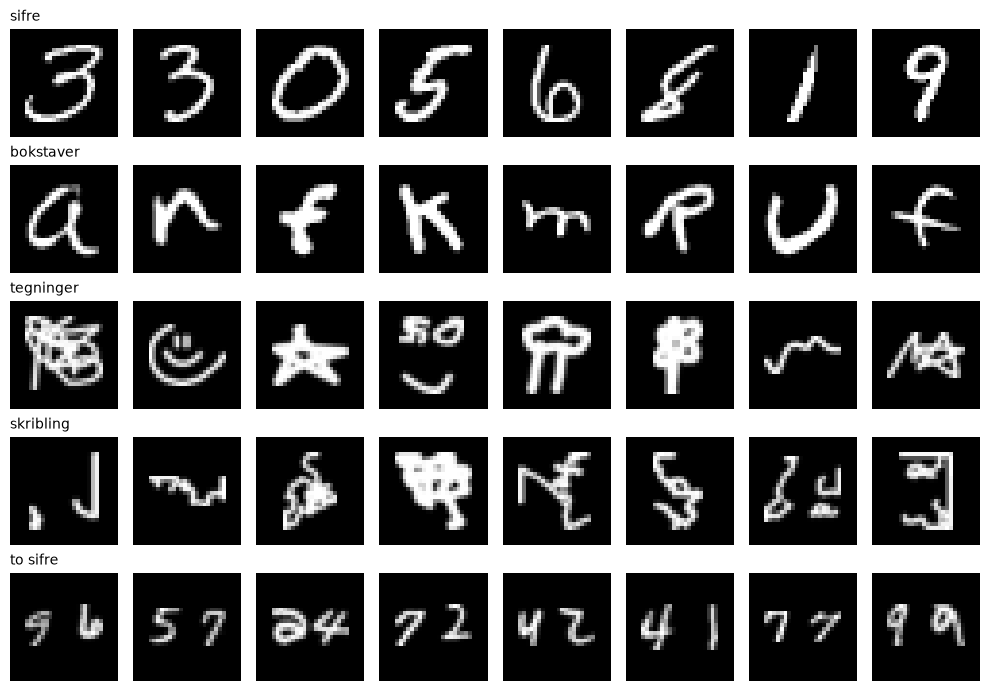

In [9]:
# Seks eksempler fra hver kilde
rader = {"sifre": sifre_train, "bokstaver": bokstaver_train, "tegninger": tegninger_train,
         "skribling": skribling_train, "to sifre": to_sifre_train}

fig, axes = plt.subplots(len(rader), 8, figsize=(10, 7))
for rad, (navn, bilder) in zip(axes, rader.items()):
    for ax, i in zip(rad, rng.choice(len(bilder), 8, replace=False)):
        ax.imshow(bilder[i], cmap="gray")
        ax.axis("off")
    rad[0].set_title(navn, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### 4f. Dataloadere

Bildene lagres som heltall 0–255 og gjøres om til normaliserte flyttall (som i notatbok 01) først når en batch skal brukes.

In [10]:
def normaliser(x):
    return (x.float() / 255 - 0.1307) / 0.3081           # samme normalisering som i notatbok 01


train_set = TensorDataset(torch.from_numpy(X_train).unsqueeze(1), torch.from_numpy(y_train).long())
test_set = TensorDataset(torch.from_numpy(X_test).unsqueeze(1), torch.from_numpy(y_test).long())

loaders = {
    "train": DataLoader(train_set, batch_size=100, shuffle=True),
    "test": DataLoader(test_set, batch_size=1000),
}

## 5. Definere CNN-et

Samme modell som i notatbok 01. Eneste forskjell er at det siste laget har 11 utganger: én per siffer og én for «ikke tall».

In [11]:
class CNN(nn.Module):
    def __init__(self, antall_klasser=11):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 32 × 14 × 14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 64 × 7 × 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, antall_klasser),
        )

    def forward(self, x):
        return self.classifier(self.features(x))      # logits, ikke sannsynligheter

## 6. Trening

Nesten samme treningsløkke som i notatbok 01: Adam, cross-entropy-tap, batcher på 100 bilder og 10 epoker.

Én forskjell: **læringsraten synker gradvis** fra 0,001 til nesten 0 (`CosineAnnealingLR`). Med fast læringsrate hoppet testnøyaktigheten flere prosentpoeng opp og ned fra epoke til epoke, fordi modellen hele tiden tar like store steg og aldri får finjustert seg. Med synkende læringsrate tar den store steg i starten og små steg mot slutten, så den lander stabilt.

In [12]:
model = CNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()
EPOKER = 10
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOKER)


def train(epoch):
    model.train()
    total_loss = 0
    for data, target in loaders["train"]:
        data, target = normaliser(data).to(device), target.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(data), target)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(data)
    return total_loss / len(loaders["train"].dataset)


def predict(loader):
    """Kjør modellen på alle bildene og returner modellens gjetninger."""
    model.eval()
    gjetninger = []
    with torch.no_grad():
        for data, _ in loader:
            gjetninger.append(model(normaliser(data).to(device)).argmax(dim=1).cpu())
    return torch.cat(gjetninger).numpy()


for epoch in range(1, EPOKER + 1):
    loss = train(epoch)
    scheduler.step()                                      # senk læringsraten litt etter hver epoke
    nøyaktighet = (predict(loaders["test"]) == y_test).mean() * 100
    print(f"Epoke {epoch:2d}: treningstap {loss:.4f}, testnøyaktighet {nøyaktighet:.2f} %")

Epoke  1: treningstap 0.1966, testnøyaktighet 97.22 %


Epoke  2: treningstap 0.0716, testnøyaktighet 98.47 %


Epoke  3: treningstap 0.0533, testnøyaktighet 98.87 %


Epoke  4: treningstap 0.0410, testnøyaktighet 99.06 %


Epoke  5: treningstap 0.0315, testnøyaktighet 99.27 %


Epoke  6: treningstap 0.0220, testnøyaktighet 99.27 %


Epoke  7: treningstap 0.0171, testnøyaktighet 99.38 %


Epoke  8: treningstap 0.0124, testnøyaktighet 99.39 %


Epoke  9: treningstap 0.0087, testnøyaktighet 99.44 %


Epoke 10: treningstap 0.0066, testnøyaktighet 99.45 %


## 7. Evaluering

Den totale nøyaktigheten forteller ikke hele historien. Vi vil vite to ting:

1. **Sifrene:** Hvor mange gjenkjennes riktig, og hvor mange blir feilaktig avvist som «ikke tall»?
2. **Ikke-tallene:** Hvor mange blir avvist, fordelt på kilde?

In [13]:
gjett = predict(loaders["test"])
er_siffer = y_test != IKKE_TALL

print("Sifre (MNIST-testsettet):")
print(f"  riktig siffer:          {(gjett[er_siffer] == y_test[er_siffer]).mean() * 100:6.2f} %")
print(f"  avvist som «ikke tall»: {(gjett[er_siffer] == IKKE_TALL).mean() * 100:6.2f} %")
print(f"  feil siffer:            {((gjett[er_siffer] != y_test[er_siffer]) & (gjett[er_siffer] != IKKE_TALL)).mean() * 100:6.2f} %")

print("\nIkke tall, andel avvist:")
for navn in ikke_tall_test:
    utvalg = kilde_test == navn
    print(f"  {navn:10s} {(gjett[utvalg] == IKKE_TALL).mean() * 100:6.2f} %  ({utvalg.sum()} bilder)")
print(f"  {'totalt':10s} {(gjett[~er_siffer] == IKKE_TALL).mean() * 100:6.2f} %")

Sifre (MNIST-testsettet):
  riktig siffer:           99.41 %
  avvist som «ikke tall»:   0.11 %
  feil siffer:              0.48 %

Ikke tall, andel avvist:
  bokstaver   99.00 %  (500 bilder)
  tegninger   99.75 %  (800 bilder)
  skribling  100.00 %  (400 bilder)
  to sifre   100.00 %  (300 bilder)
  totalt      99.65 %


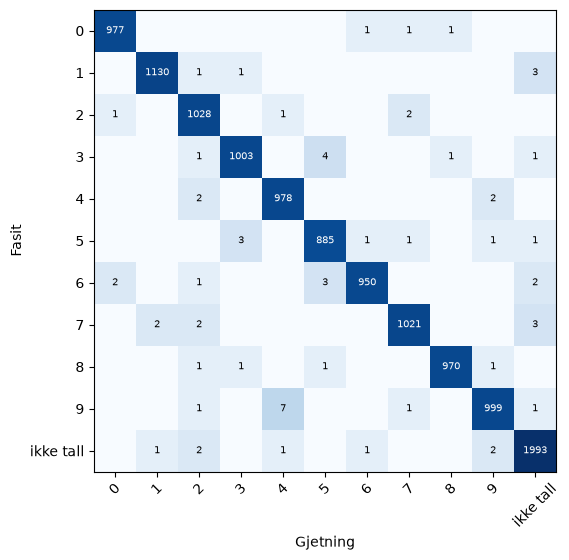

In [14]:
# Forvekslingsmatrise: rad = fasit, kolonne = modellens gjetning. Kolonne og rad 10 er «ikke tall».
forveksling = np.zeros((11, 11), dtype=int)
np.add.at(forveksling, (y_test, gjett), 1)

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(np.log1p(forveksling), cmap="Blues")
for i in range(11):
    for j in range(11):
        if forveksling[i, j]:
            ax.text(j, i, forveksling[i, j], ha="center", va="center", fontsize=7,
                    color="white" if i == j else "black")
ax.set_xticks(range(11), KLASSENAVN, rotation=45)
ax.set_yticks(range(11), KLASSENAVN)
ax.set_xlabel("Gjetning")
ax.set_ylabel("Fasit")
plt.show()

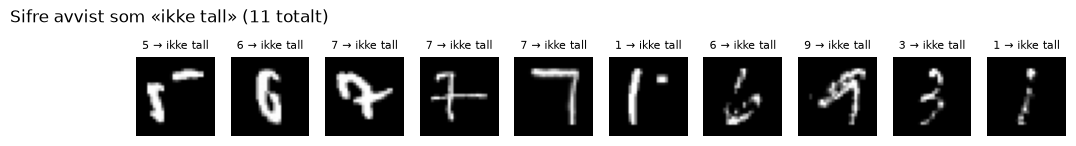

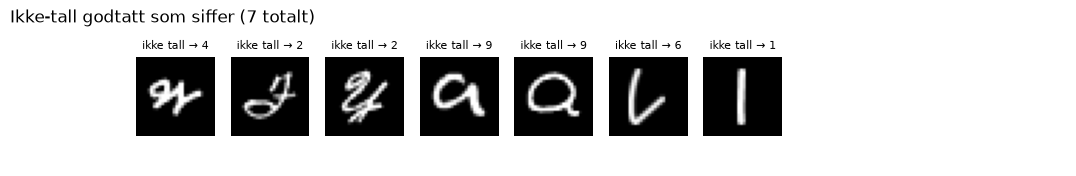

In [15]:
# Hva går galt? Øverst: sifre som ble avvist. Nederst: ikke-tall som ble godtatt som et siffer.
def vis_feil(indekser, tittel):
    fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
    fig.suptitle(f"{tittel} ({len(indekser)} totalt)", x=0.02, ha="left")
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indekser[:10]):
        ax.imshow(X_test[i], cmap="gray")
        ax.set_title(f"{KLASSENAVN[y_test[i]]} → {KLASSENAVN[gjett[i]]}", fontsize=8)
    plt.show()


vis_feil(np.flatnonzero(er_siffer & (gjett == IKKE_TALL)), "Sifre avvist som «ikke tall»")
vis_feil(np.flatnonzero(~er_siffer & (gjett != IKKE_TALL)), "Ikke-tall godtatt som siffer")

In [16]:
torch.save(model.state_dict(), "mnist_cnn_ikke_tall.pt")

## 8. Eksport til ONNX

Samme innpakning som i notatbok 01: normalisering og softmax bygges inn, så nettsiden sender inn et 28×28-bilde med verdier 0–1 og får 11 sannsynligheter tilbake. Sannsynlighet nummer 11 (indeks 10) er «ikke tall».

Modellen lagres som `docs/mnist_cnn_ikke_tall.onnx`, ved siden av den gamle. Nettsiden bruker fortsatt `mnist_cnn.onnx` til `index.html` er oppdatert til å håndtere 11 utganger.

In [17]:
import copy


class DigitModelForWeb(nn.Module):
    """Modellen + normalisering + softmax, klar for nettleseren."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):                 # x: [1, 1, 28, 28], verdier 0–1, hvitt tall på svart
        x = (x - 0.1307) / 0.3081         # samme normalisering som i treningen
        return F.softmax(self.model(x), dim=1)


web_model = DigitModelForWeb(copy.deepcopy(model).cpu()).eval()

os.makedirs("docs", exist_ok=True)
torch.onnx.export(
    web_model,
    (torch.rand(1, 1, 28, 28),),
    "docs/mnist_cnn_ikke_tall.onnx",
    input_names=["image"],
    output_names=["probs"],
    external_data=False,
)
print("Lagret docs/mnist_cnn_ikke_tall.onnx,", os.path.getsize("docs/mnist_cnn_ikke_tall.onnx") // 1024, "kB")

[torch.onnx] Obtain model graph for `DigitModelForWeb([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `DigitModelForWeb([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Lagret docs/mnist_cnn_ikke_tall.onnx, 1856 kB
